# <a id='toc1_'></a>[Gradient Boosting](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Gradient Boosting](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
    - [Separação treino e teste - validação cruzada](#toc1_2_1_)    
    - [Aplicando o Gradient Boosting](#toc1_2_2_)    
    - [Otimização de hiperparâmetros](#toc1_2_3_)    
    - [Analisando os resultados](#toc1_2_4_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Nesse notebook, iremos implementar o modelo de Gradient Boosting ao nosso dataset. Depois de implementá-lo, também vamos otimizar seus hiperparâmetros e comparar os resultados obtidos com outros modelos.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Vamos iniciar coletando e tratando os dados que iremos utilizar, como feito no notebook [01.A - Baseline](01.A%20-%20Baseline.ipynb). Dessa vez, como vamos realizar a otimização, vamos dividir nosso conjunto em dados de treino e dados de teste.

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

ATTRIBUTES = [
    "epicenter_distance",
    "geodesic_distance",
    "azimuth_degree",
    "magnitude",
    "magnitude_type",
    "depth",
    "first_arrival_time_delta",
    "arrival_time_delta",
    "land_fraction",
    "origin_plate"
]

TARGET = [
    "amplitude_factor_log10"
]

df_earthquakes = pd.read_csv("../00 - Coleta e Tratamento de Dados/Data/earthquake_dataset_treated.csv")

X = df_earthquakes.reindex(ATTRIBUTES, axis=1)
y = df_earthquakes.reindex(TARGET, axis=1)

CATEGORICAL_ATTRIBUTES = ["magnitude_type", "origin_plate"]
NUMERICAL_ATTRIBUTES = [
    column for column in X.columns
    if column not in CATEGORICAL_ATTRIBUTES
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_ATTRIBUTES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_ATTRIBUTES
        )
    ]
)

### <a id='toc1_2_1_'></a>[Separação treino e teste - validação cruzada](#toc0_)

Para dividir os dados de treino e teste, de forma à estimar as métricas dos modelos induzidos de uma forma mais confiável, iremos utilizar a técnica de **Validação cruzada**. Mais especificamente, aplicaremos o método $k$-fold, a partir da biblioteca `scikit-learn`.

In [3]:
from sklearn.model_selection import KFold

NUM_FOLDS = 10
RANDOM_STATE = 424242

TEST_SIZE = 0.1

df_earthquakes = df_earthquakes.reindex(ATTRIBUTES + TARGET, axis=1)

y_bins = pd.qcut(
    y.values.ravel(),
    q=5,
    labels=False,
    duplicates="drop"
)

idx = df_earthquakes.index
train_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_bins)

df_train = df_earthquakes.iloc[train_idx]
df_test = df_earthquakes.iloc[test_idx]

X_train = df_train.reindex(ATTRIBUTES, axis=1)
y_train = df_train.reindex(TARGET, axis=1)

X_test = df_test.reindex(ATTRIBUTES, axis=1)
y_test = df_test.reindex(TARGET, axis=1)

kf = KFold(NUM_FOLDS, shuffle=True, random_state=RANDOM_STATE)

### <a id='toc1_2_2_'></a>[Aplicando o Gradient Boosting](#toc0_)

Vamos utilizar o `Gradient Boosting` do **scikit-learn** para induzir nosso modelo, de acordo com a referência [2].

A métrica que utilizaremos de referência será o RMSE, que é a raiz do erro quadrático médio das previsões do nosso modelo.

As métricas foram:
 0 - 0.5026757401283332
 1 - 0.3985272795619006
 2 - 0.4839674231244086
 3 - 0.701201364957095
 4 - 0.3925752269460201
 5 - 0.24685647514543943
 6 - 0.3915985631800095
 7 - 0.5280587441311873
 8 - 0.4551631527342623
 9 - 0.5817242988992287


A média das métricas é de: 0.4682348268807884


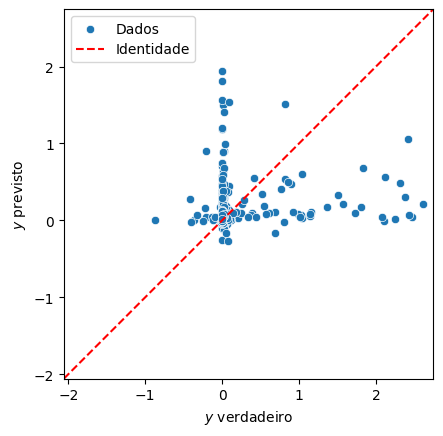

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error
import seaborn as sns
import numpy as np

gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE
        ))
    ]
)

def test_kf(model, X=X, y=y, kf=kf, plot=True):
    metrics = []
    true_y = []
    pred_y = []

    for train_idx, test_idx in kf.split(X):

        X_train_, X_test_ = X.iloc[train_idx], X.iloc[test_idx]
        y_train_, y_test_ = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train_, y_train_.values.ravel())

        true_y_ = y_test_
        pred_y_ = model.predict(X_test_)
        
        true_y.append(true_y_)
        pred_y.append(pred_y_)

        RMSE = root_mean_squared_error(true_y_, pred_y_)

        metrics.append(RMSE)

    if plot:
        print("As métricas foram:\n", *[f"{i} - {metric}\n" for i, metric in enumerate(metrics)])
        print()
        print("A média das métricas é de:", np.mean(metrics))

        true_y = np.concatenate(true_y).ravel()
        pred_y = np.concatenate(pred_y).ravel()

        min_val = min(true_y.min(), pred_y.min())
        max_val = max(true_y.max(), pred_y.max())

        interval = [min_val * 0.95, max_val * 1.05]

        ax = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
        ax.plot(interval, interval, "r--", label="Identidade")

        ax.set(
            xlabel="$y$ verdadeiro",
            ylabel="$y$ previsto",
            xlim=interval,
            ylim=interval,
            aspect="equal",
        )
        ax.legend();
    
    return metrics
    
gb_metrics = test_kf(gb_model)

Podemos ver que já houve uma tentativa diferente do modelo para tentar prever cada uma das ampitudes de uma forma diferente, se concentrado em acertos no meio. Entretanto, modelo inicial apresentou desempenho semelhante ao baseline, indicando que essa configuração de hiperparâmetros não foi capaz de melhorar significativamente as previsões. Vamos ver como ele se comporta ao otmizar os os hiperparâmetros utilizando o optuna.

### <a id='toc1_2_3_'></a>[Otimização de hiperparâmetros](#toc0_)

Para os atributos, iremos definir as seguintes opções:

- `n_estimators`: varia de 50 a 300, definindo a quantidade de árvores adicionadas sequencialmente ao modelo. Um número maior permite realizar mais etapas de correção dos erros, aumentando a capacidade do modelo.
- `learning_rate`: varia de 0,01 a 0,3, controlando a contribuição de cada árvore para a previsão final. Valores menores fazem com que o modelo aprenda de maneira mais gradual, geralmente exigindo um número maior de árvores.
- `max_depth`: varia de 2 a 10, controlando a profundidade máxima das árvores individuais e, consequentemente, a complexidade das relações que cada árvore consegue representar.
- `min_samples_split`: varia de 2 a 20, definindo a quantidade mínima de amostras necessária para que um nó possa ser dividido e ajudando a controlar o crescimento das árvores.
- `min_samples_leaf`: varia de 1 a 10, estabelecendo a quantidade mínima de amostras que cada folha pode possuir, reduzindo o risco de que as árvores se ajustem excessivamente a poucas observações.

In [ ]:
def create_model_instance(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 300),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.3, log=True
        ),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
    }
    
    
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(**params))
    ]
    
    
    gb_model = Pipeline(steps)
    
    return gb_model

Agora, vamos definir a função objetivo, que vai medir a métrica do modelo.

In [7]:
def objective_function(trial, X, y, kf, num_folds):
    model = create_model_instance(trial)
    
    metrics = test_kf(model, X, y, kf, plot=False)
    
    return np.mean(metrics)

Então, vamos criar o objeto de estudo, que será responsável por buscar os melhores hiperparâmetros do espaço delimitado

In [11]:
from optuna import create_study, delete_study, get_all_study_summaries

STUDY_NAME = "Studies/gb_tiamat"
STORAGE = f"sqlite:///{STUDY_NAME}.db"

studies = get_all_study_summaries(storage=STORAGE)

if any(study.study_name == STUDY_NAME for study in studies):
    delete_study(
        study_name=STUDY_NAME,
        storage=STORAGE
    )

study_obj = create_study(
    direction="minimize",
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
)

[I 2026-11-16 09:51:07,145] A new study created in RDB with name: Studies/gb_tiamat


Utilizando o funtools. podemos criar nossa função objetiva parcial

In [12]:
from functools import partial

partial_objective_function = partial(
    objective_function, X=X_train, y=y_train, kf=kf, num_folds=NUM_FOLDS
)

E, por fim, otimizamos o estudo a partir do método `optimize`. Vamos utilizar um número de tentativas inicial como 100.

In [13]:
N_TRIALS = 100

study_obj.optimize(partial_objective_function, n_trials=N_TRIALS)

[I 2026-11-16 09:51:15,920] Trial 0 finished with value: 0.47970238913127333 and parameters: {'n_estimators': 263, 'learning_rate': 0.04333467417236364, 'max_depth': 9, 'min_samples_split': 13, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.47970238913127333.
[I 2026-11-16 09:51:18,258] Trial 1 finished with value: 0.4884849607449805 and parameters: {'n_estimators': 201, 'learning_rate': 0.2223934946540335, 'max_depth': 4, 'min_samples_split': 8, 'min_samples_leaf': 8}. Best is trial 0 with value: 0.47970238913127333.
[I 2026-11-16 09:51:19,860] Trial 2 finished with value: 0.42893575538991086 and parameters: {'n_estimators': 171, 'learning_rate': 0.05381735263034389, 'max_depth': 2, 'min_samples_split': 8, 'min_samples_leaf': 8}. Best is trial 2 with value: 0.42893575538991086.
[I 2026-11-16 09:51:22,296] Trial 3 finished with value: 0.41535774764778016 and parameters: {'n_estimators': 280, 'learning_rate': 0.011675814246180388, 'max_depth': 2, 'min_samples_split': 7, 'min_samp

### <a id='toc1_2_4_'></a>[Analisando os resultados](#toc0_)

Vamos observar os resultados do estudo

In [14]:
df = study_obj.trials_dataframe()

df

,number,value,datetime_start,datetime_complete,duration,params_learning_rate,params_max_depth,params_min_samples_leaf,params_min_samples_split,params_n_estimators,system_attrs_tpe:relative_params:0,state
0,0,0.479702,2026-11-16 09:51:10.889656,2026-11-16 09:51:15.900265,0 days 00:00:05.010609,0.043335,9,3,13,263,NaN,COMPLETE
1,1,0.488485,2026-11-16 09:51:15.926668,2026-11-16 09:51:18.241860,0 days 00:00:02.315192,0.222393,4,8,8,201,NaN,COMPLETE
2,2,0.428936,2026-11-16 09:51:18.264981,2026-11-16 09:51:19.843713,0 days 00:00:01.578732,0.053817,2,8,8,171,NaN,COMPLETE
3,3,0.415358,2026-11-16 09:51:19.865376,2026-11-16 09:51:22.279689,0 days 00:00:02.414313,0.011676,2,4,7,280,NaN,COMPLETE
4,4,0.474315,2026-11-16 09:51:22.305254,2026-11-16 09:51:24.037211,0 days 00:00:01.731957,0.223410,3,10,3,183,NaN,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.412109,2026-11-16 09:53:43.542929,2026-11-16 09:53:44.460671,0 days 00:00:00.917742,0.024083,2,5,2,71,"{""learning_rate"": 0.02408315757956469, ""max_de...",COMPLETE
96,96,0.412082,2026-11-16 09:53:44.494073,2026-11-16 09:53:45.642054,0 days 00:00:01.147981,0.018803,2,5,4,80,"{""learning_rate"": 0.018803204850464317, ""max_d...",COMPLETE
97,97,0.413695,2026-11-16 09:53:45.669522,2026-11-16 09:53:46.568073,0 days 00:00:00.898551,0.020840,2,4,2,83,"{""learning_rate"": 0.02084046155949298, ""max_de...",COMPLETE
98,98,0.412168,2026-11-16 09:53:46.589861,2026-11-16 09:53:47.874058,0 days 00:00:01.284197,0.018665,2,5,3,93,"{""learning_rate"": 0.018665055918098326, ""max_d...",COMPLETE


O melhor resultado pode ser obtido através do atributo `best_trial`

In [15]:
best_trial = study_obj.best_trial

print(f"Número do melhor trial: {best_trial.number}")
print(f"Parâmetros do melhor trial: {best_trial.params}")

Número do melhor trial: 93
Parâmetros do melhor trial: {'n_estimators': 84, 'learning_rate': 0.02014582499131264, 'max_depth': 2, 'min_samples_split': 3, 'min_samples_leaf': 5}


Vamos criar um modelo com o melhor conjunto de hiperparâmetros encontrados e checar seu desempenho.

O RMSE calculado é de: 0.37798455848354845


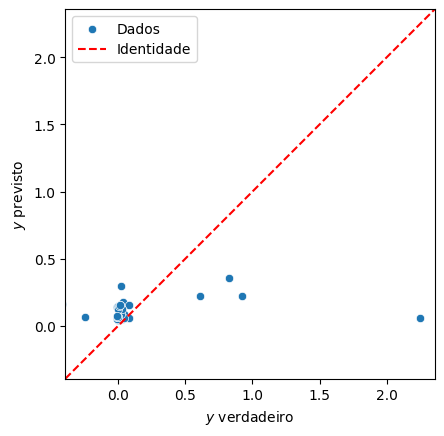

In [16]:
model = create_model_instance(best_trial)
model.fit(X_train, y_train.values.ravel())

true_y = np.asarray(y_test).ravel()
pred_y = np.asarray(model.predict(X_test)).ravel()

RMSE = root_mean_squared_error(true_y, pred_y)

min_val = min(true_y.min(), pred_y.min())
max_val = max(true_y.max(), pred_y.max())

interval = [min_val * 0.95, max_val * 1.05]

eixo = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
eixo.plot(interval, interval, "r--", label="Identidade")

eixo.set(
    xlabel="$y$ verdadeiro",
    ylabel="$y$ previsto",
    xlim=interval,
    ylim=interval,
    aspect="equal",
)
eixo.legend();

print(f"O RMSE calculado é de: {RMSE}")

Aparentemente, o modelo de Gradient Boositng otimizado conseguiu um RMSE com cerca de 0.048 pontos a menos se comparado ao modelo baseline, apresentando o menor RMSE até então. Contudo, vemos que a maior parte dos seus acertos está nos valores mais baixos, enquanto os valores maiores não são tão bem previstos.

É importante considerar que os valores elevados de amplitude podem estar associados tanto a eventos sísmicos de maior intensidade quanto a possíveis artefatos de medição ou limitações presentes nas etapas de tratamento dos dados.

Vamos ver como ficou a importância dos parâmetros de busca de acordo com o optuna

In [19]:
import optuna.visualization as vis 

vis.plot_param_importances(study_obj)

Pelo gráfico, vemos como o número mínimo de folhas é o hiperparâmetro mais importantes, seguido do número de estimadores e do número mínimo de amostras para o split.

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Sendo assim, nosso modelo de Gradient Boosting apresentou um RMSE inferior ao obtido pelo modelo baseline, prevendo bem os valores nas faixas mais baixas. Entretanto, para testes com amplitudes maiores, ele não conseguiu prever de forma tão adequada.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. **CASSAR, Daniel R.** *ATP-203 1.1 - Tratamento de dados com pandas*. Campinas: Ilum Escola de Ciência, 2026.
2. **SILVA, Pedro Lucas Miranda da.** *T26 - Gradient Boosting*. Campinas: ILUM Escola de Ciência, 2026. Disponível em: <https://github.com/drcassar/biblioteca_real/blob/main/Aprendizado%20de%20M%C3%A1quina/Gradient%20Boosting/T26%20-%20Pedro%20Lucas%20Miranda%20da%20Silva%20de%20S%C3%A1.ipynb>.
3. **CASSAR, Daniel R.** *ATP-203 7.1 - Otimização de hiperparâmetros com optuna*. Campinas: Ilum Escola de Ciência, 2026.